# 01 - Data Preparation (V2.0)

**What's different from V1:** every raster write now goes through `raster_io_v2.write_geotiff()`, which always forces `driver="GTiff"`. This is the fix for the `CPLE_NotSupportedError` you hit -- V1 silently inherited the `JP2OpenJPEG` driver from the raw `.jp2` inputs all the way through to the NDVI/NDWI/NDBI float32 writes, where JP2 cannot write floats. See `raster_io_v2.py`'s module docstring for the full explanation.

**Also new:**
- Raw bands are validated and their metadata printed *before* any processing starts (`inspect_all_raw_bands()`).
- If `config_v2.AOI_PATH` doesn't exist (your current situation -- `mumbai_aoi.gpkg` was never uploaded), an AOI is auto-derived from your training polygons' bounds instead of stopping and asking you to draw one.
- Raw bands are converted to float32 reflectance right after clipping.

**Before running:** put your Sentinel-2 band files in `data/raw/sentinel2/` and check `scripts/config_v2.py`'s `RAW_BANDS` / `TRAINING_POLYGONS_PATH`.

**Output used by the next notebook:** `data/processed/final_stack.tif`

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path('..') / 'scripts'))

import config_v2 as config
import preprocessing_v2 as preprocessing
import raster_io_v2 as rio


## Validate raw inputs before doing any work

In [2]:
try:
    preprocessing.inspect_all_raw_bands()
except FileNotFoundError as e:
    print(e)
    raise


Band  Driver         Dtype    CRS          Res        Size         NoData
B02   JP2OpenJPEG    uint16   EPSG:32643   10.0       10980x10980  None
B03   JP2OpenJPEG    uint16   EPSG:32643   10.0       10980x10980  None
B04   JP2OpenJPEG    uint16   EPSG:32643   10.0       10980x10980  None
B08   JP2OpenJPEG    uint16   EPSG:32643   10.0       10980x10980  None
B11   JP2OpenJPEG    uint16   EPSG:32643   20.0       5490x5490   None
B12   JP2OpenJPEG    uint16   EPSG:32643   20.0       5490x5490   None


## AOI check

If `config.AOI_PATH` doesn't exist, the next cell (inside `run_full_preprocessing()`) will automatically derive one from your training polygons and save it to `qgis/auto_generated_aoi.gpkg` -- open that in QGIS afterwards if you want to sanity-check the extent.

In [3]:
print('AOI file configured at:', config.AOI_PATH)
print('Exists:', config.AOI_PATH.exists())
if not config.AOI_PATH.exists():
    print('-> Will auto-derive an AOI from', config.TRAINING_POLYGONS_PATH.name)


AOI file configured at: D:\2.0\project_v2\qgis\mumbai_aoi.gpkg
Exists: False
-> Will auto-derive an AOI from training.gpkg


## Run the full preprocessing pipeline

In [4]:
final_stack_path = preprocessing.run_full_preprocessing()


Step 0: Validating raw band files...
Band  Driver         Dtype    CRS          Res        Size         NoData
B02   JP2OpenJPEG    uint16   EPSG:32643   10.0       10980x10980  None
B03   JP2OpenJPEG    uint16   EPSG:32643   10.0       10980x10980  None
B04   JP2OpenJPEG    uint16   EPSG:32643   10.0       10980x10980  None
B08   JP2OpenJPEG    uint16   EPSG:32643   10.0       10980x10980  None
B11   JP2OpenJPEG    uint16   EPSG:32643   20.0       5490x5490   None
B12   JP2OpenJPEG    uint16   EPSG:32643   20.0       5490x5490   None

Step 1: Clipping bands to AOI (and converting to reflectance)...
No AOI file found at D:\2.0\project_v2\qgis\mumbai_aoi.gpkg. Auto-deriving an AOI from the bounds of training.gpkg, buffered by 300 m.
Saved auto-generated AOI -> D:\2.0\project_v2\qgis\auto_generated_aoi.gpkg (open it in QGIS to check it looks right)
Clipped B02 -> D:\2.0\project_v2\data\processed\B02_clip.tif (dtype=float32)
Clipped B03 -> D:\2.0\project_v2\data\processed\B03_clip.tif (dt

## Confirm the fix: final_stack.tif is a real GeoTIFF

In [5]:
info = rio.inspect_raster(config.FINAL_STACK_PATH)
for k, v in info.items():
    print(f'{k}: {v}')
assert info['driver'] == 'GTiff', 'Expected GTiff -- something upstream is still wrong.'
print('\nOK: final_stack.tif is a proper GeoTIFF.')


path: D:\2.0\project_v2\data\processed\final_stack.tif
driver: GTiff
dtype: float32
count: 9
width: 5166
height: 8738
crs: EPSG:32643
resolution: (10.0, 10.0)
nodata: nan
bounds: (256950.0, 2109970.0, 308610.0, 2197350.0)

OK: final_stack.tif is a proper GeoTIFF.


## Quick visual sanity check: true-color preview + NDVI

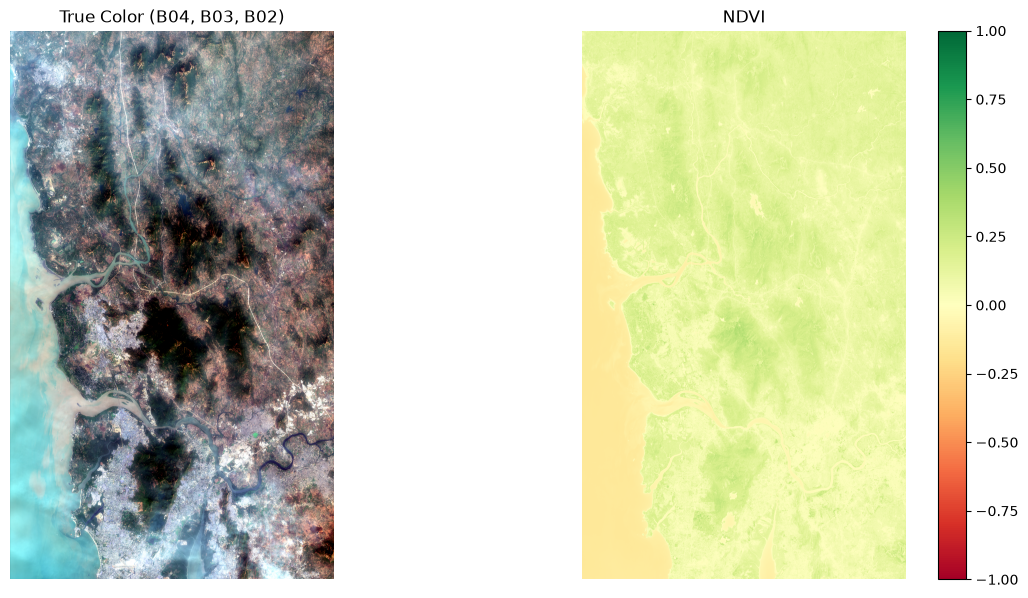

In [6]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np

with rasterio.open(config.FINAL_STACK_PATH) as src:
    band_idx = {name: i + 1 for i, name in enumerate(config.FEATURE_NAMES)}
    red = src.read(band_idx['B04'])
    green = src.read(band_idx['B03'])
    blue = src.read(band_idx['B02'])
    ndvi = src.read(band_idx['NDVI'])

def normalize(arr):
    p2, p98 = np.nanpercentile(arr, (2, 98))
    return np.clip((arr - p2) / (p98 - p2 + 1e-9), 0, 1)

rgb = np.dstack([normalize(red), normalize(green), normalize(blue)])

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(rgb)
axes[0].set_title('True Color (B04, B03, B02)')
axes[0].axis('off')

im = axes[1].imshow(ndvi, cmap='RdYlGn', vmin=-1, vmax=1)
axes[1].set_title('NDVI')
axes[1].axis('off')
plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()


## Done

`final_stack.tif` (9 bands: B02, B03, B04, B08, B11, B12, NDVI, NDWI, NDBI, all float32, driver=GTiff) is ready.

**Next notebook:** `02_extract_training_data_v2.ipynb`